# Домашняя работа. Кластеризация

В первой части нужно вручную разделить точки из шести файлов на кластеры и найти их центры. Во второй — сравнить `MiniBatchKMeans` и `DBSCAN` на разных распределениях.

**Важно:** для заданий №3 и №4 расстояние манхэттенское, для остальных — евклидово.

## Часть 1. Кластеризация ЕГЭ

### 1. Загружаем точки и смотрим на их распределение

Файлы `0.xls` и `1.xls` я перевёл в `.xlsx`, чтобы все шесть наборов читались одинаково. В некоторых файлах есть заголовки столбцов, а в других сразу идут числа, поэтому при чтении оставляю только строки с числовыми координатами.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from pathlib import Path

folder = Path('.')
if not (folder / '0.xlsx').exists():
    folder = Path('EGE')

def read_points(number):
    df = pd.read_excel(folder / f'{number}.xlsx', header=None)
    df = df.apply(pd.to_numeric, errors='coerce').dropna()
    return df.to_numpy()

points = [read_points(i) for i in range(6)]
for i, p in enumerate(points):
    print(f'Файл {i}: {len(p)} точек')

Файл 0: 100 точек
Файл 1: 9999 точек
Файл 2: 1000 точек
Файл 3: 10000 точек
Файл 4: 500 точек
Файл 5: 9999 точек


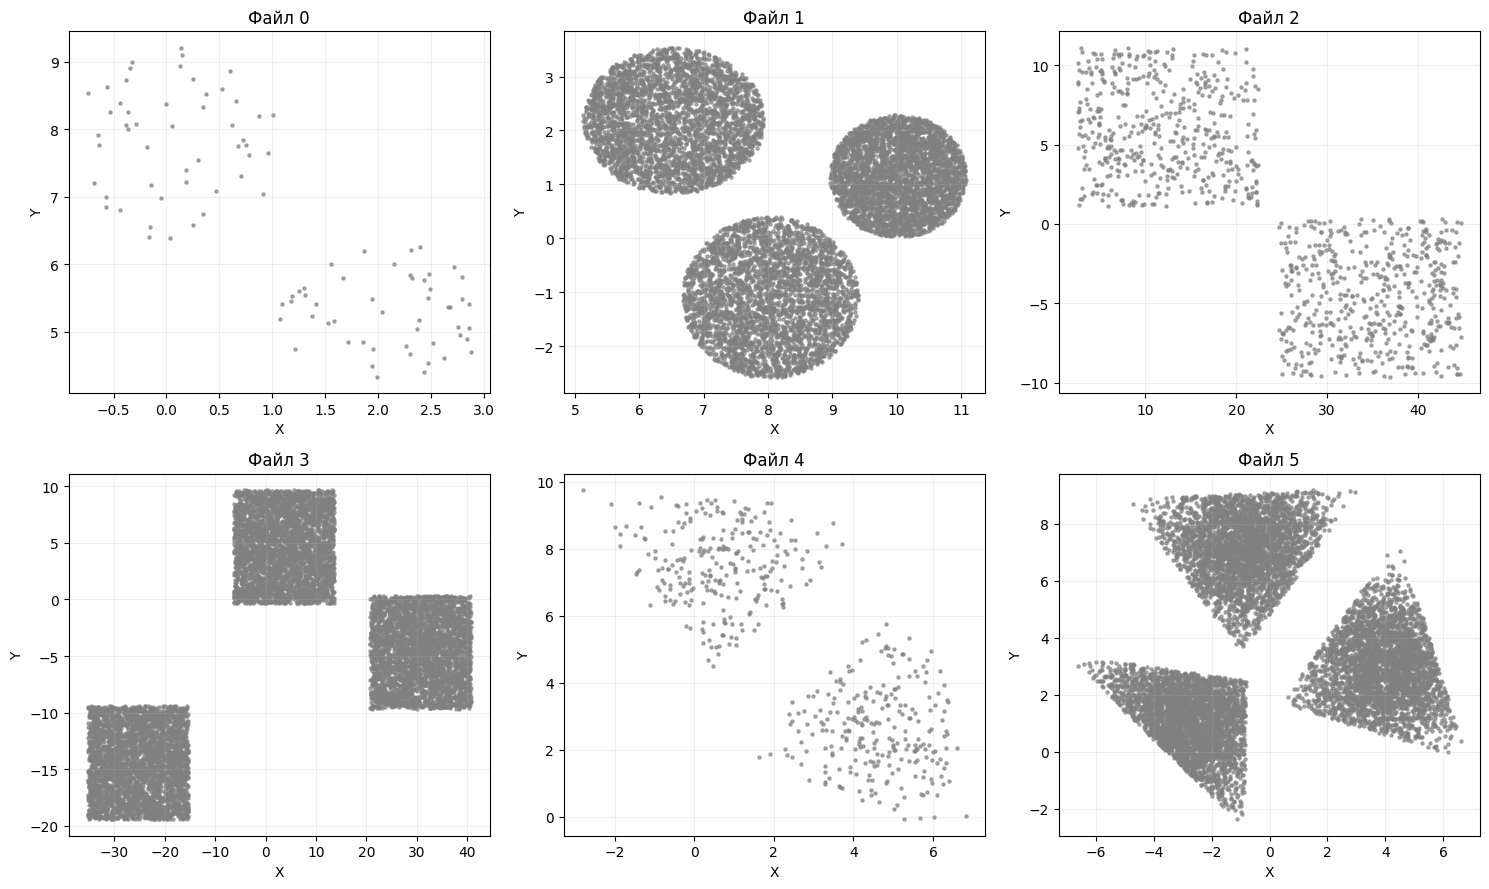

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, ax in enumerate(axes.flat):
    p = points[i]
    ax.scatter(p[:, 0], p[:, 1], s=5, color='gray', alpha=0.65)
    ax.set_title(f'Файл {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2. Делим точки на кластеры вручную

Границы выбираю по первому рисунку. Для большинства файлов хватает прямых. В файле №1 три круглые группы, поэтому беру три **примерных центра на глаз** и отношу каждую точку к ближайшему из них. Это не обучение KMeans: координаты выбраны вручную и не меняются.

В файле №5 три треугольные группы, их удобно разделить двумя наклонными линиями.

In [3]:
def manual_clusters(number, p):
    x, y = p[:, 0], p[:, 1]

    if number == 0:
        return (y < 6.5).astype(int)

    if number == 1:
        centers = np.array([[6.5, 2], [8, -1.15], [9.95, 1.15]])
        return cdist(p, centers).argmin(axis=1)

    if number == 2:
        return (x >= 24).astype(int)

    if number == 3:
        return np.select([x < -12, x < 17], [0, 1], default=2)

    if number == 4:
        return (y - x <= 2).astype(int)

    # Верхняя группа отделена двумя наклонными прямыми.
    top = (y > -0.3 * x + 3.2) & (y > x + 3.5)
    return np.select([top, x > 0], [1, 2], default=0)

labels_ege = [manual_clusters(i, points[i]) for i in range(6)]
for i, labels in enumerate(labels_ege):
    print(f'Файл {i}:', np.bincount(labels), 'точек по кластерам')

Файл 0: [48 52] точек по кластерам
Файл 1: [3333 3333 3333] точек по кластерам
Файл 2: [476 524] точек по кластерам
Файл 3: [3429 3284 3287] точек по кластерам
Файл 4: [250 250] точек по кластерам
Файл 5: [3333 3333 3333] точек по кластерам


### 3. Находим центральные точки кластеров

Центром по условию считаем **одну из имеющихся точек**, для которой сумма расстояний до всех остальных точек кластера минимальна. Это называют медоидом.

Для расчёта расстояний используем `cdist`. `euclidean` — обычное расстояние по прямой, `cityblock` — манхэттенское расстояние (сумма модулей разностей координат).

In [4]:
def find_center(p, metric):
    distances = cdist(p, p, metric=metric)
    sums = distances.sum(axis=1)
    return p[np.argmin(sums)]

center_points = []
answer_rows = []
center_rows = []

for number in range(6):
    p = points[number]
    labels = labels_ege[number]
    metric = 'cityblock' if number in (3, 4) else 'euclidean'

    centers = []
    for cluster_id in np.unique(labels):
        cluster_points = p[labels == cluster_id]
        center = find_center(cluster_points, metric)
        centers.append(center)
        center_rows.append({
            'Файл': number,
            'Кластер': int(cluster_id),
            'Число точек': len(cluster_points),
            'Центр X': center[0],
            'Центр Y': center[1]
        })

    centers = np.array(centers)
    center_points.append(centers)
    mean_center = centers.mean(axis=0) * 1000
    answer_rows.append({
        'Файл': number,
        'X * 1000': mean_center[0],
        'Y * 1000': mean_center[1],
        'Целое X': int(mean_center[0]),
        'Целое Y': int(mean_center[1])
    })

print('Центральные точки каждого кластера:')
display(pd.DataFrame(center_rows).round(3))

Центральные точки каждого кластера:


,Файл,Кластер,Число точек,Центр X,Центр Y
0,0,0,48,0.048,8.053
1,0,1,52,2.034,5.289
2,1,0,3333,6.470,2.170
3,1,1,3333,8.040,-1.109
4,1,2,3333,10.023,1.154
5,2,0,476,11.334,5.966
6,2,1,524,34.926,-4.695
7,3,0,3429,-25.131,-14.413
8,3,1,3284,3.518,4.654
9,3,2,3287,30.850,-4.517


### 4. Красим кластеры и отмечаем их центры

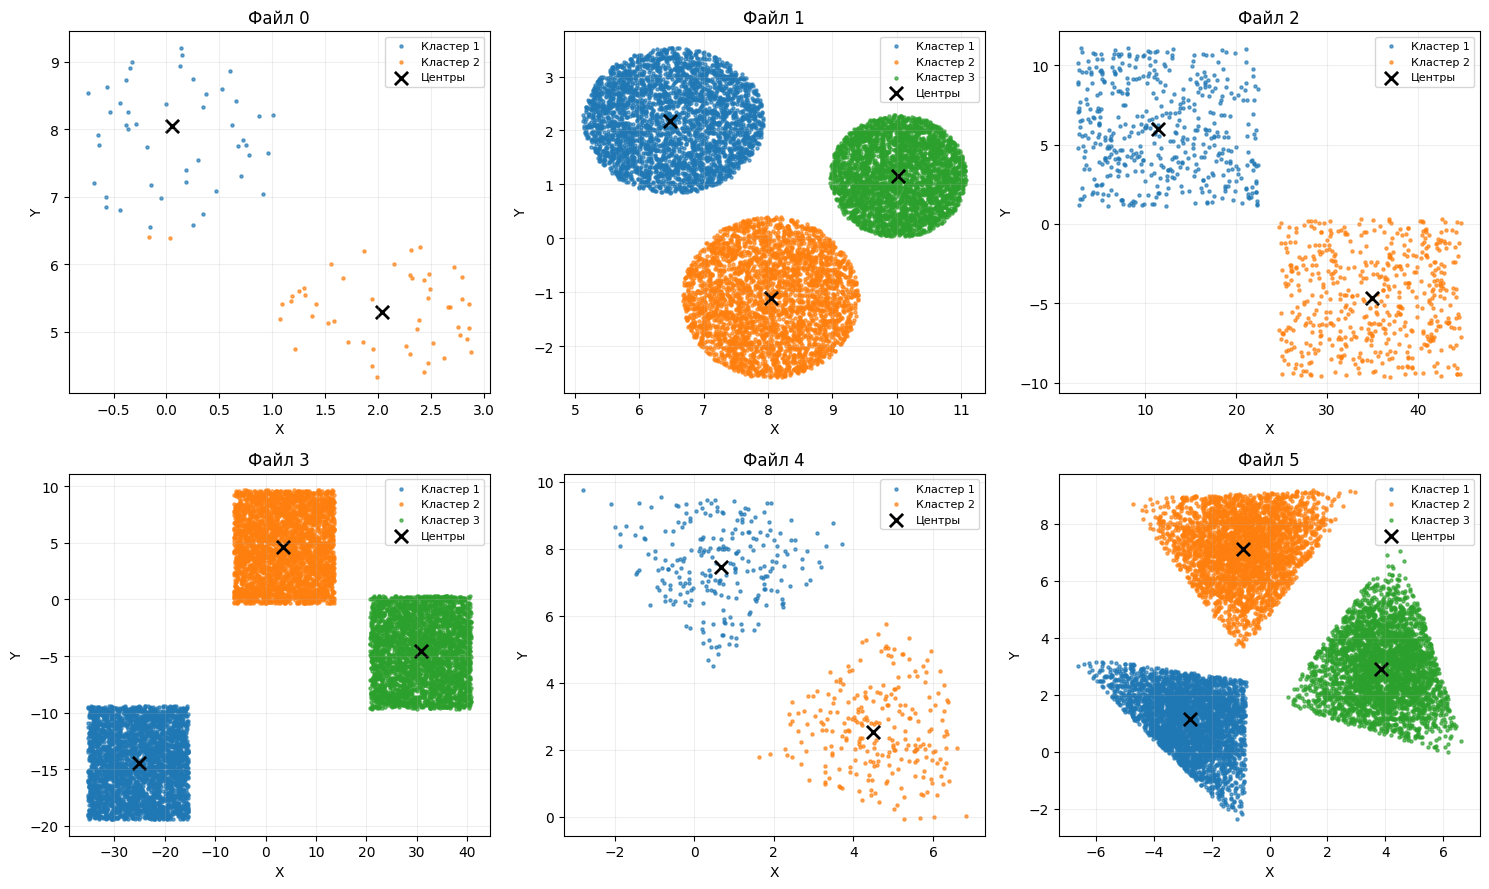

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
colors = ['tab:blue', 'tab:orange', 'tab:green']

for i, ax in enumerate(axes.flat):
    p = points[i]
    labels = labels_ege[i]

    for k in np.unique(labels):
        group = p[labels == k]
        ax.scatter(group[:, 0], group[:, 1], s=5,
                   color=colors[k], alpha=0.65, label=f'Кластер {k + 1}')

    centers = center_points[i]
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='x',
               s=90, linewidths=2, label='Центры')
    ax.set_title(f'Файл {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 5. Итоговые ответы

Берём среднее арифметическое координат **центральных точек** внутри одного файла и умножаем каждую координату на 1000. В последних двух столбцах дробная часть отброшена, если нужен целый ответ.

In [6]:
answers = pd.DataFrame(answer_rows)
display(answers.round(3))

for row in answer_rows:
    print(f"Файл {row['Файл']}: X = {row['X * 1000']:.2f}, "
          f"Y = {row['Y * 1000']:.2f}")

,Файл,X * 1000,Y * 1000,Целое X,Целое Y
0,0,1041.006,6671.173,1041,6671
1,1,8177.531,738.419,8177,738
2,2,23130.216,635.342,23130,635
3,3,3078.894,-4758.945,3078,-4758
4,4,2588.540,4996.568,2588,4996
5,5,61.652,3723.362,61,3723


Файл 0: X = 1041.01, Y = 6671.17
Файл 1: X = 8177.53, Y = 738.42
Файл 2: X = 23130.22, Y = 635.34
Файл 3: X = 3078.89, Y = -4758.95
Файл 4: X = 2588.54, Y = 4996.57
Файл 5: X = 61.65, Y = 3723.36


## Часть 2. Сравнение MiniBatchKMeans и DBSCAN

`MiniBatchKMeans` делит точки на заранее заданное количество кластеров. `DBSCAN` ищет плотные области, поэтому ему необязательно заранее сообщать количество кластеров. Точки, которые он считает шумом, получают метку `-1`.

Сначала создаём шесть наборов, как в исходном задании. Затем для каждого набора запускаем оба алгоритма и рисуем получившиеся группы.

In [7]:
import time
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler

np.random.seed(0)
n_samples = 1500

noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = (np.random.rand(n_samples, 2), None)

X, y = datasets.make_blobs(n_samples=n_samples, random_state=170)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
aniso = (np.dot(X, transformation), y)

varied = datasets.make_blobs(n_samples=n_samples,
                             cluster_std=[1.0, 2.5, 0.5],
                             random_state=170)

Параметры `eps` и `min_samples` подбирал по графикам: старался, чтобы DBSCAN выделял столько же групп, сколько ожидается в данных. Для точек без структуры это не получается осмысленно, и это нормально.

In [8]:
# Название, данные, число кластеров для KMeans, eps для DBSCAN, min_samples
all_datasets = [
    ('Окружности', noisy_circles, 2, 0.30, 5),
    ('Полумесяцы', noisy_moons, 2, 0.30, 5),
    ('Разная плотность', varied, 3, 0.20, 10),
    ('Вытянутые группы', aniso, 3, 0.20, 7),
    ('Обычные группы', blobs, 3, 0.22, 5),
    ('Без структуры', no_structure, 3, 0.18, 5)
]

two_means = cluster.MiniBatchKMeans(n_clusters=3, random_state=0,
                                   n_init=10, batch_size=256)
dbscan = cluster.DBSCAN(eps=0.3, min_samples=5)

clustering_algorithms = (
    ('MiniBatchKMeans', two_means),
    ('DBSCAN', dbscan)
)

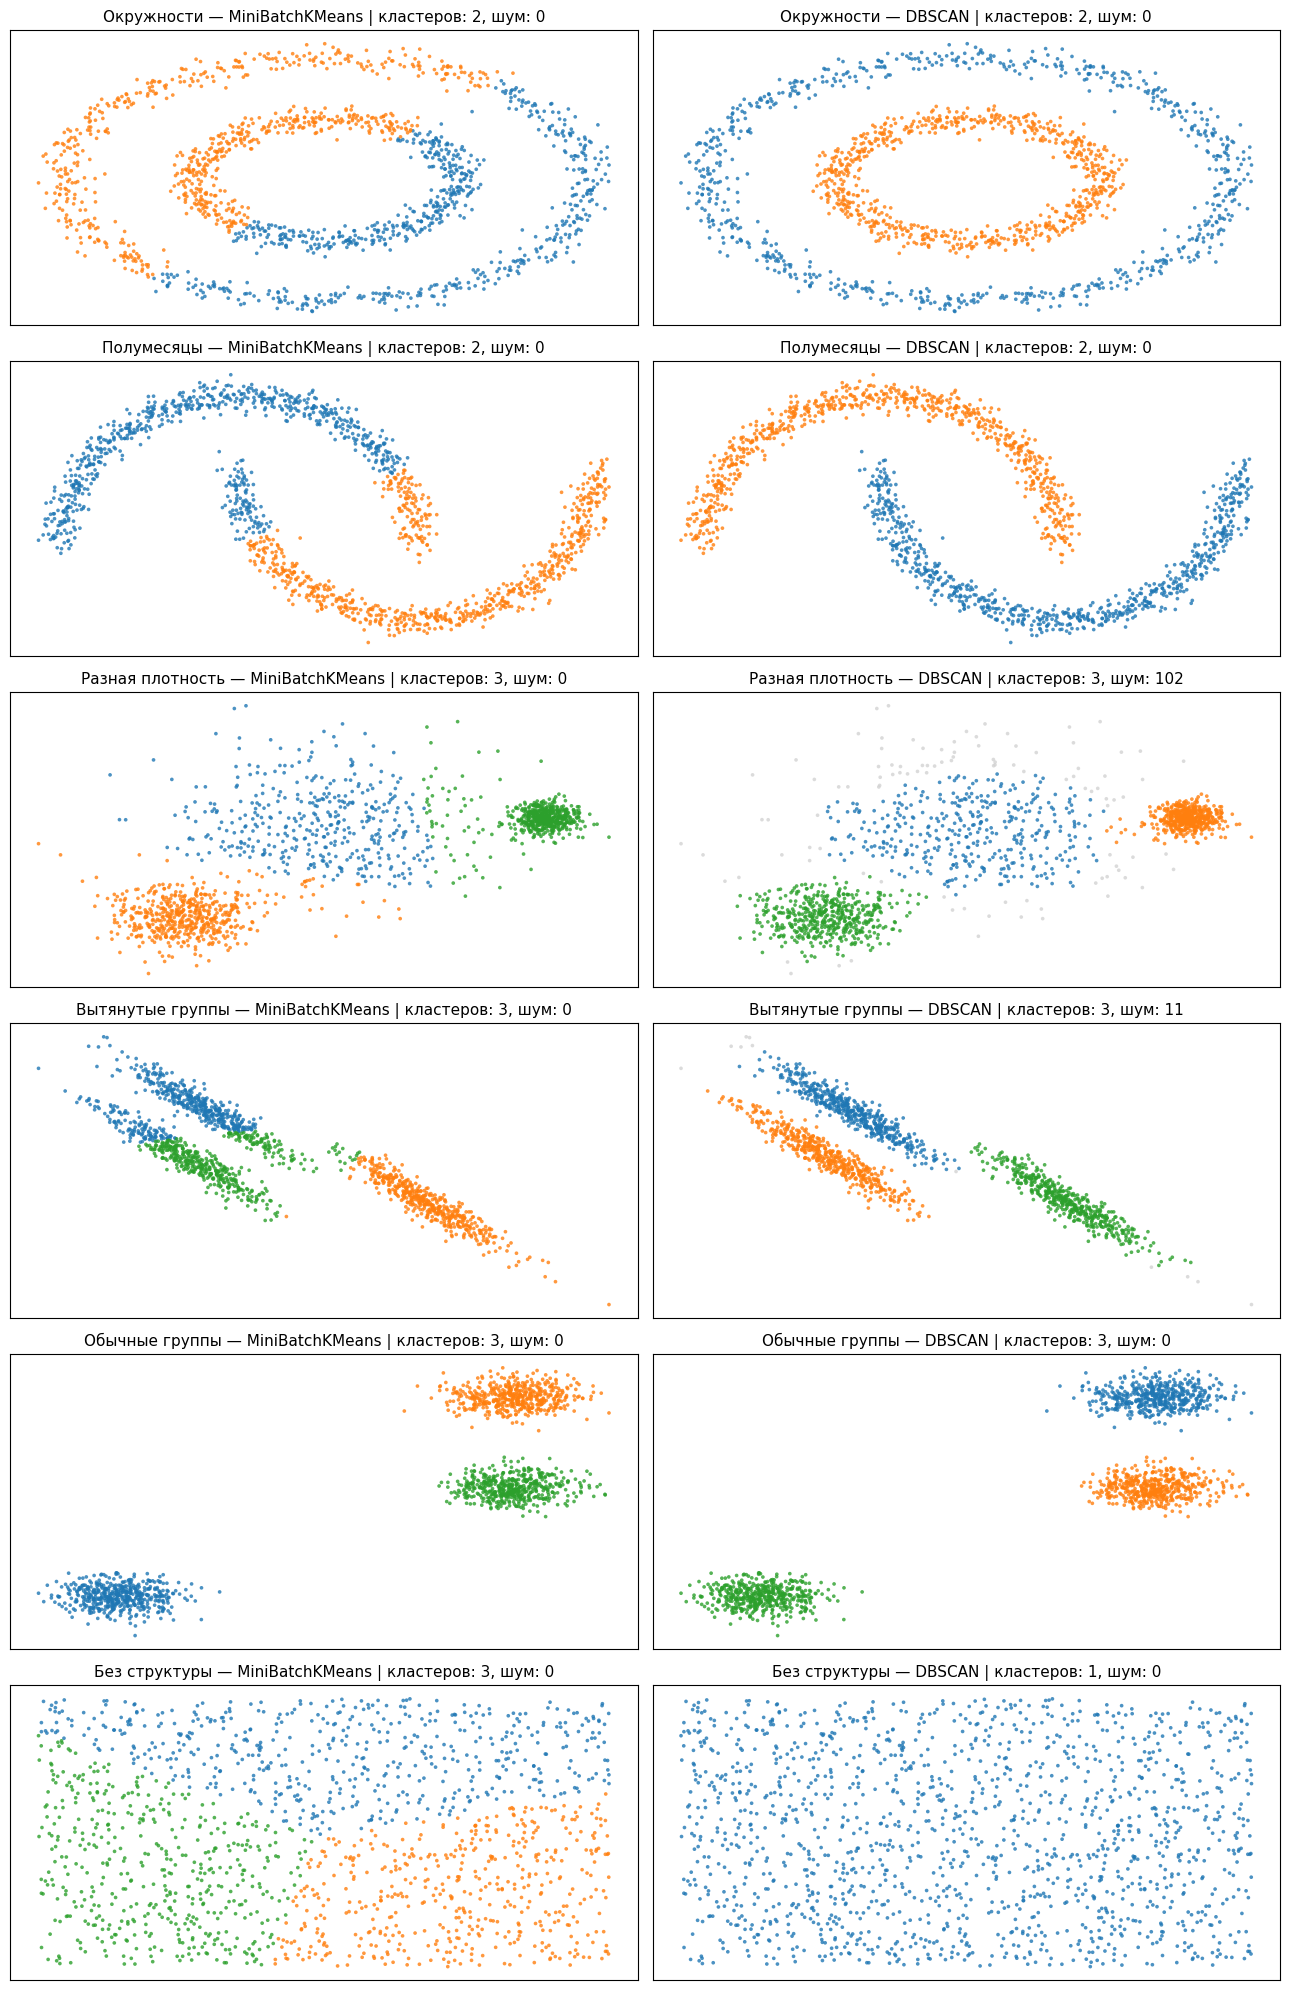

In [9]:
fig, axes = plt.subplots(6, 2, figsize=(13, 20))
results_ml = []

for i, (data_name, dataset, n_clusters, eps, min_samples) in enumerate(all_datasets):
    X, y = dataset
    X = StandardScaler().fit_transform(X)

    # У каждого набора могут быть свои параметры.
    two_means.set_params(n_clusters=n_clusters)
    dbscan.set_params(eps=eps, min_samples=min_samples)

    for j, (name, algorithm) in enumerate(clustering_algorithms):
        start = time.time()
        labels = algorithm.fit_predict(X)
        seconds = time.time() - start

        count = len(set(labels)) - (1 if -1 in labels else 0)
        noise = int((labels == -1).sum())
        results_ml.append({
            'Данные': data_name,
            'Алгоритм': name,
            'Кластеров': count,
            'Шум': noise,
            'Время, с': round(seconds, 3)
        })

        ax = axes[i, j]
        for k in np.unique(labels):
            group = X[labels == k]
            color = 'lightgray' if k == -1 else plt.cm.tab10(k % 10)
            ax.scatter(group[:, 0], group[:, 1], s=7,
                       c=[color], alpha=0.8, edgecolors='none')

        ax.set_title(f'{data_name} — {name} | кластеров: {count}, шум: {noise}',
                     fontsize=11)
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

In [10]:
print('Результаты сравнения:')
display(pd.DataFrame(results_ml))

Результаты сравнения:


,Данные,Алгоритм,Кластеров,Шум,"Время, с"
0,Окружности,MiniBatchKMeans,2,0,0.018
1,Окружности,DBSCAN,2,0,0.007
2,Полумесяцы,MiniBatchKMeans,2,0,0.011
3,Полумесяцы,DBSCAN,2,0,0.006
4,Разная плотность,MiniBatchKMeans,3,0,0.007
5,Разная плотность,DBSCAN,3,102,0.008
6,Вытянутые группы,MiniBatchKMeans,3,0,0.006
7,Вытянутые группы,DBSCAN,3,11,0.006
8,Обычные группы,MiniBatchKMeans,3,0,0.006
9,Обычные группы,DBSCAN,3,0,0.009


### Вывод по второй части

- **Окружности и полумесяцы.** DBSCAN лучше сохраняет необычную форму групп. KMeans стремится делить данные вокруг центров и поэтому разрезает изогнутые группы.
- **Обычные группы.** Оба алгоритма выделяют три кластера.
- **Вытянутые группы.** DBSCAN может учитывать вытянутую форму, если подобрать `eps` и `min_samples`.
- **Разная плотность.** DBSCAN чувствителен к выбранному радиусу: часть редких точек он помечает как шум, а KMeans всегда распределяет все точки по кластерам.
- **Без структуры.** KMeans всё равно разбивает точки на три группы, потому что мы заранее указали `n_clusters=3`. DBSCAN при выбранных параметрах видит одну общую область. Это показывает, почему результат алгоритма не всегда означает, что реальные группы существуют.

**Итог:** универсального лучшего алгоритма нет. KMeans удобен для компактных групп и известного числа кластеров, DBSCAN — для групп сложной формы и выделения шума.